# Supplementary Figure S18: gene-set enrichment of the TSS effect list

The ranked list is the one of Fig S17: for each of the 14,221 TSSs (one per gene) Cohen's *d* of the
row-z-scored GD feature (cancer − healthy), per task (cohort `no_deep`). Positive = GD higher in cancer
plasma (a deeper nucleosome-depleted dip at the TSS).

Source data: `data/no_deep/figS18_*.csv` and `figS18_summary.json`, written by
`export/export_figS18_gene_sets.py` (also the C8 cell-type classes, `figS18_c8_classes.csv`, keyword rules in
the exporter), `export/export_figS18_matched_10k.py` and `export/export_figS18_zhu_es.py`.

## 0. How the GSEA is computed

Pre-ranked GSEA (`gseapy.prerank` 1.3.1, 1,000 permutations, background = the 14,221 TSS genes): the
enrichment score (ES) is the maximum deviation of the running sum along the list sorted by *d*; NES = ES
normalized by the permuted sets of the same sign; FDR per collection (Hallmark, C8, the pre-specified sets).
Leading-edge genes are in `lead_genes` / `n_leading_edge` of `figS18_gsea.csv`. The figure below uses the
look-alike test of the next section instead of the GSEA permutation null.

In [1]:
import os, json

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch ------------------------------------------------------------------
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    p = os.path.join(_DATA, name)
    assert os.path.exists(p), f"{p} missing - run COHORT_VARIANT={COHORT} python export/export_figS18_gene_sets.py"
    return p


def out_path(name):
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

TASKS = ["brca_crc", "pancan"]
TASK_LABELS = {"brca_crc": "Healthy vs BRCA + CRC", "pancan": "Healthy vs PANCAN"}
TASK_COLORS = {"brca_crc": "#0173B2", "pancan": "#DE8F05"}
SETS = ["zhu_promoter", "hk", "pau"]
SET_LABELS = {"zhu_promoter": "Zhu promoter genes (RNA region set)", "hk": "housekeeping genes (Fig 1)", "pau": "genes unexpressed in blood (Fig 1)"}
SET_COLORS = {"zhu_promoter": "#CC78BC", "hk": "#029E73", "pau": "#949494"}

tss = pd.read_csv(data_path("figS18_tss_sets.csv"))
sets = pd.read_csv(data_path("figS18_sets.csv"))
gsea = pd.read_csv(data_path("figS18_gsea.csv"))
matched = pd.read_csv(data_path("figS18_gsea_matched.csv"))
curves = pd.read_csv(data_path("figS18_prespecified_curves.csv"))
hits = pd.read_csv(data_path("figS18_prespecified_hits.csv"))
with open(data_path("figS18_summary.json")) as fh:
    summary = json.load(fh)
CONTRASTS = list(summary["contrasts"])                      # the two tasks first, then the cancer types
TYPES = [c for c in CONTRASTS if c.startswith("type_")]
CLABEL = {c: v["label"] for c, v in summary["contrasts"].items()}
CLABEL_SHORT = {c: CLABEL[c].replace("Healthy vs ", "").replace(" cancer", "").replace(" naive nsclc", " (NSCLC)") for c in CONTRASTS}
NCANCER = {c: v["n_cancer"] for c, v in summary["contrasts"].items()}
N = int(summary["n_tss"])
SETMEANS = matched[(matched["statistic"] == "cohen_d") & (matched["matching"] == "gc_coverage")]
matched_all = matched


def runs(contrast, collection, statistic="cohen_d"):
    return gsea[(gsea["contrast"] == contrast) & (gsea["collection"] == collection) & (gsea["statistic"] == statistic)].copy()


def pre(contrast, s, statistic="cohen_d"):
    r = runs(contrast, "prespecified", statistic); r = r[r["term"] == s]
    assert len(r) == 1, (contrast, s, statistic)
    return r.iloc[0]


c8cls = pd.read_csv(data_path("figS18_c8_classes.csv"))      # study/tissue prefix, cell-type part and cell-type class of every C8 set (exporter)
C8 = {t: runs(t, "c8_cell_type").merge(c8cls[["term", "cell_class"]], on="term") for t in TASKS}
CLASS_ORDER = C8["pancan"].groupby("cell_class")["nes"].median().sort_values(ascending=False).index.tolist()


print(f"{N} TSSs; contrasts: " + ", ".join(f"{CLABEL_SHORT[c]} (n = {NCANCER[c]})" for c in CONTRASTS))


display(sets)


cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


14221 TSSs; contrasts: BRCA + CRC (n = 80), PANCAN (n = 203), Breast (n = 54), Pancreatic (n = 34), Ovarian (n = 28), Gastric (n = 27), Colorectal (n = 26), Bile duct (n = 24), Lung (NSCLC) (n = 10)


,set,label,n_genes_in_bed,n_in_tss_universe_19376,n_removed_by_tss_filter,n_mapped_to_14221
0,zhu_promoter,Zhu promoter genes (RNA region set),265,258,54,204
1,hk,housekeeping genes (Fig 1),2126,2126,703,1423
2,pau,genes unexpressed in blood (Fig 1),751,751,222,529


## Figure S18

Every panel compares a set of TSSs with 10,000 random sets of the same size drawn from the 14,221 TSSs
with the same composition over quarters of GC, panel-of-normals window coverage and panel-of-normals dip
depth ("look-alike" TSSs). Statistic: rank-AUC of the signed *d*; z = (set − look-alike mean) / SD;
two-sided empirical p; BH q within a collection.

- a, b: Zhu et al. promoter genes (the RNA comparator's regions), GSEA running enrichment score with the
  empirical p of its ES among 10,000 look-alike ESs (`export/export_figS18_zhu_es.py`);
- c Hallmark, d Reactome: sets with q < 0.05 in at least one task;
- e C8 cell-type signatures, one dot per set with q < 0.05 in that task, rows = cell-type class.

Filled = q < 0.05 in that task, open = not; dot area = number of TSSs (`export/export_figS18_matched_10k.py`).

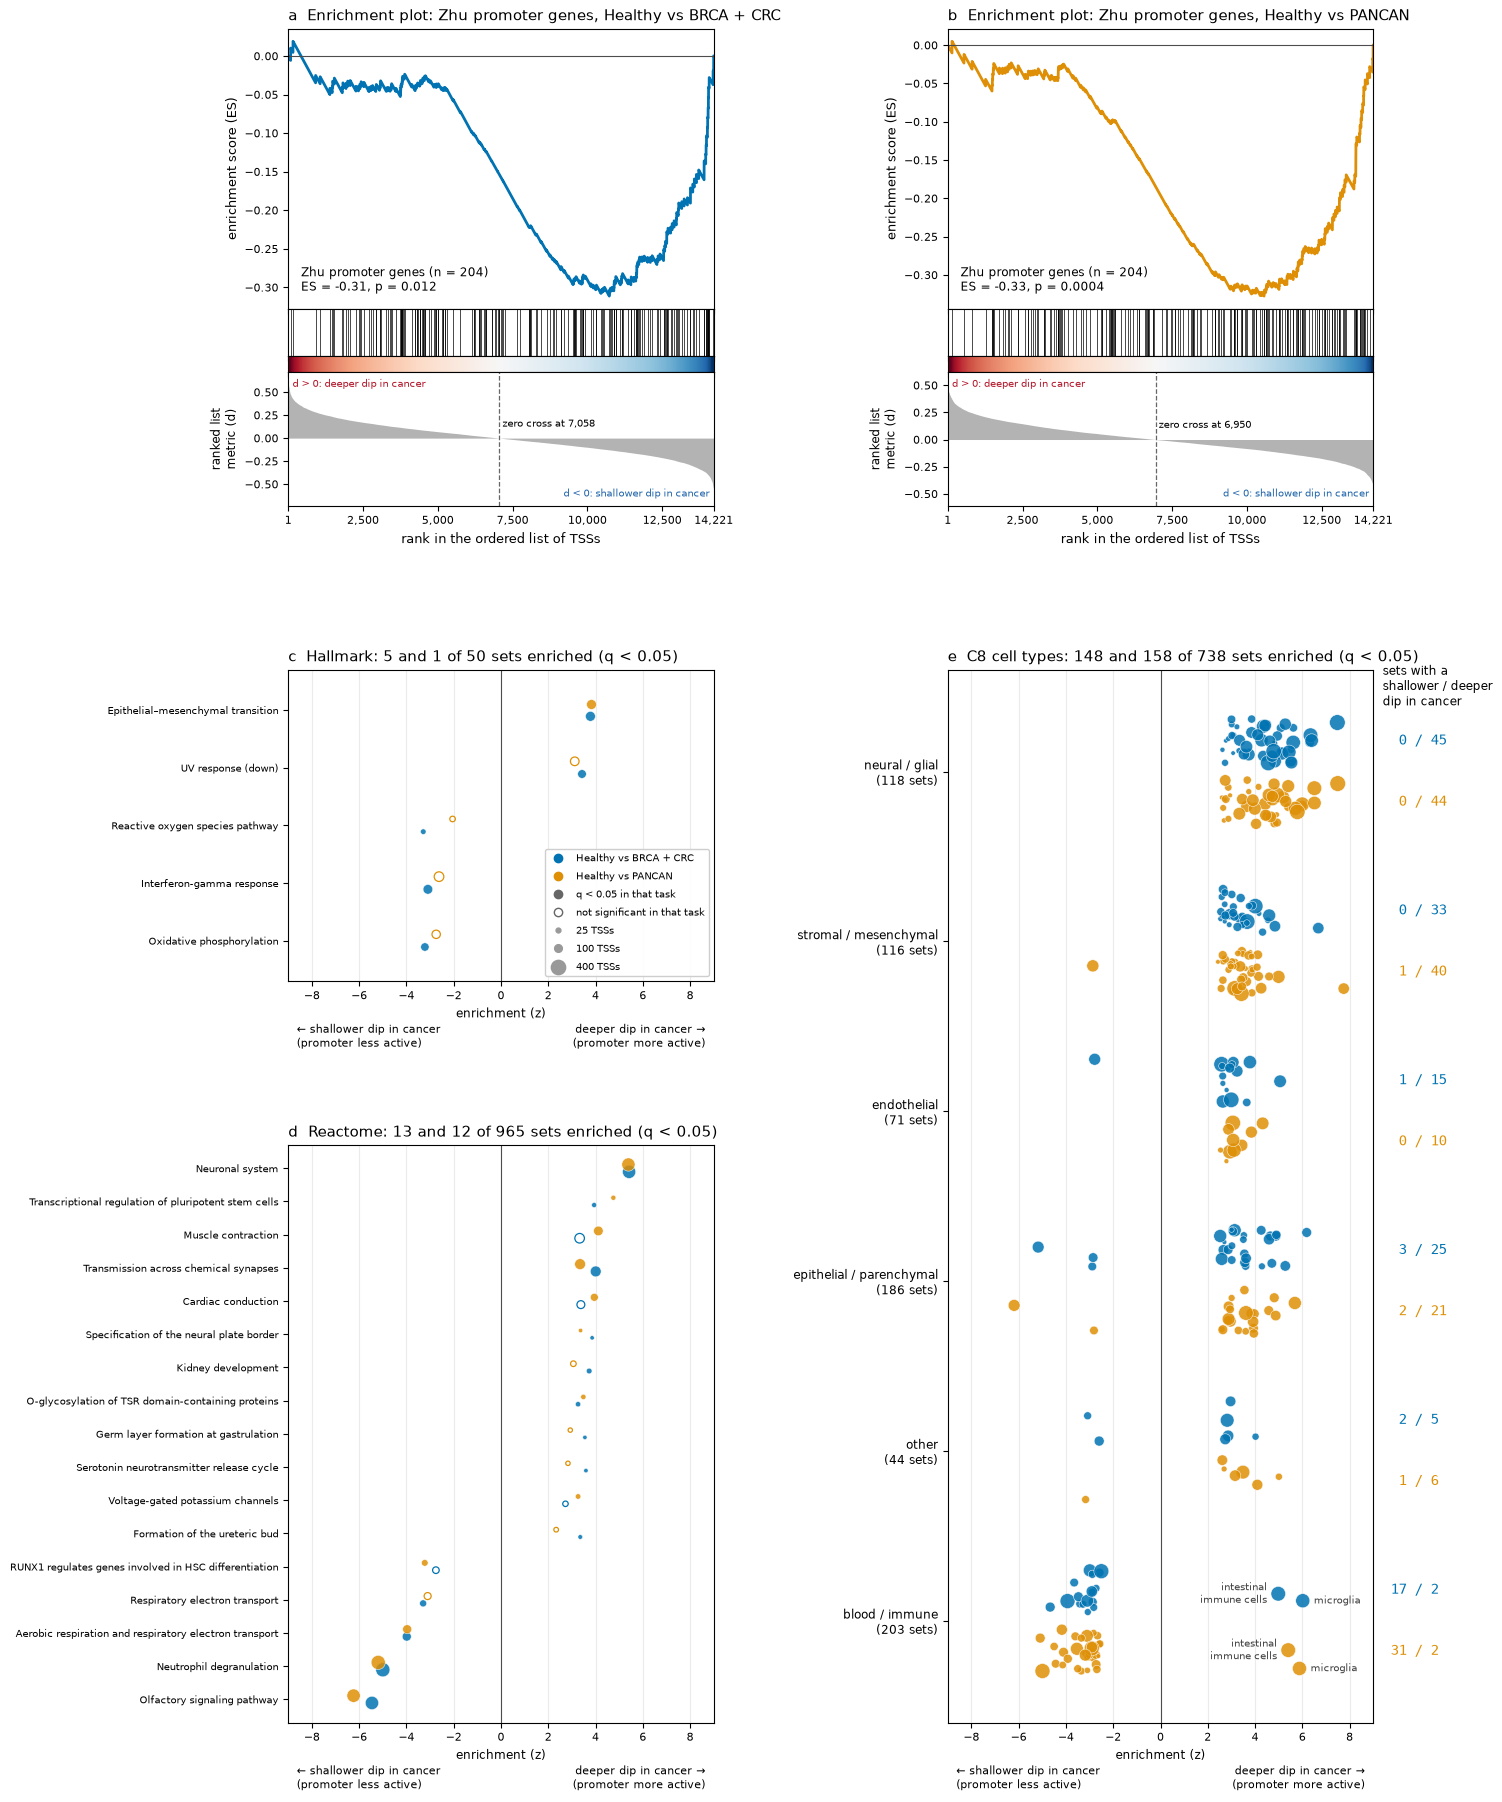

hallmark      Healthy vs BRCA + CRC   :   50 sets, differ from look-alikes (q < 0.05):    5 (3 shallower, 2 deeper)
hallmark      Healthy vs PANCAN       :   50 sets, differ from look-alikes (q < 0.05):    1 (0 shallower, 1 deeper)
c8_cell_type  Healthy vs BRCA + CRC   :  738 sets, differ from look-alikes (q < 0.05):  148 (23 shallower, 125 deeper)
c8_cell_type  Healthy vs PANCAN       :  738 sets, differ from look-alikes (q < 0.05):  158 (35 shallower, 123 deeper)
reactome      Healthy vs BRCA + CRC   :  965 sets, differ from look-alikes (q < 0.05):   13 (4 shallower, 9 deeper)
reactome      Healthy vs PANCAN       :  965 sets, differ from look-alikes (q < 0.05):   12 (4 shallower, 8 deeper)


In [2]:
# ---- Fig S18: a, b the Zhu promoter set, c Hallmark, d Reactome, e C8 cell types, all against look-alike TSSs ----
LA = pd.read_csv(data_path("figS18_gsea_matched_10k.csv"))
assert int(LA["n_null"].iloc[0]) == 10000 and "reactome" in set(LA["collection"]), "rerun export/export_figS18_matched_10k.py"
LA["sig"] = LA["rank_auc_signed_d_q"] < 0.05
LA["z"] = LA["rank_auc_signed_d_z"]


def la_table(coll):
    """Look-alike results of one collection, wide over the two tasks; only sets with q < 0.05 in >= 1 task."""
    x = LA[LA["collection"] == coll].pivot_table(index="term", columns="contrast", values=["z", "sig", "n_genes_matched"], aggfunc="first")
    keep = x["sig"][TASKS].astype(bool).any(axis=1)
    return x[keep]


SET_NAMES = {   # names as printed in the figure where lower-casing the MSigDB name loses an acronym or a hyphen
    "HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION": "Epithelial\u2013mesenchymal transition",
    "HALLMARK_UV_RESPONSE_DN": "UV response (down)",
    "HALLMARK_INTERFERON_GAMMA_RESPONSE": "Interferon-gamma response",
    "REACTOME_O_GLYCOSYLATION_OF_TSR_DOMAIN_CONTAINING_PROTEINS": "O-glycosylation of TSR domain-containing proteins",
    "REACTOME_RUNX1_REGULATES_TRANSCRIPTION_OF_GENES_INVOLVED_IN_DIFFERENTIATION_OF_HSCS": "RUNX1 regulates genes involved in HSC differentiation",
    "REACTOME_VOLTAGE_GATED_POTASSIUM_CHANNELS": "Voltage-gated potassium channels",
}
C8_LABELS = {   # the blood / immune sets on the 'deeper dip in cancer' side, named in the panel
    "GAO_LARGE_INTESTINE_ADULT_CJ_IMMUNE_CELLS": ("intestinal\nimmune cells", "left"),
    "ZHONG_PFC_C3_MICROGLIA": ("microglia", "right"),
}


def nice(term):
    if term in SET_NAMES:
        return SET_NAMES[term]
    s = term.replace("HALLMARK_", "").replace("REACTOME_", "").replace("_", " ").lower()
    return s[:1].upper() + s[1:]


ZLIM = float(np.ceil(LA.loc[LA["sig"], "z"].abs().max() + 0.5))
XLAB = "enrichment (z)"
XLAB_LEFT = "\u2190 shallower dip in cancer\n(promoter less active)"
XLAB_RIGHT = "deeper dip in cancer \u2192\n(promoter more active)"
size = lambda n: 6 + np.asarray(n, float) / 4.0     # dot area ~ number of TSSs in the set


def dots(ax, x, y, n, sig, t):
    sig = np.asarray(sig, bool)
    ax.scatter(np.asarray(x)[sig], np.asarray(y)[sig], s=size(np.asarray(n)[sig]), color=TASK_COLORS[t], alpha=0.85, edgecolors="white", linewidths=0.4, zorder=3)
    ax.scatter(np.asarray(x)[~sig], np.asarray(y)[~sig], s=size(np.asarray(n)[~sig]), facecolors="none", edgecolors=TASK_COLORS[t], linewidths=0.9, zorder=3)


def style(ax, title):
    ax.axvline(0, color="0.3", lw=0.8); ax.set_xlim(-ZLIM, ZLIM); ax.set_xlabel(XLAB, fontsize=8.5)
    ax.annotate(XLAB_LEFT, xy=(0.02, 0), xycoords="axes fraction", xytext=(0, -30), textcoords="offset points", ha="left", va="top", fontsize=8)
    ax.annotate(XLAB_RIGHT, xy=(0.98, 0), xycoords="axes fraction", xytext=(0, -30), textcoords="offset points", ha="right", va="top", fontsize=8)
    ax.grid(axis="x", alpha=0.25); ax.set_axisbelow(True); ax.tick_params(axis="x", labelsize=8)
    ax.set_title(title, loc="left", fontsize=10.5)


def set_panel(ax, coll, letter, label):
    """Hallmark / Reactome: one row per set that differs from its look-alikes, one dot per task."""
    x = la_table(coll)
    order = x["z"][TASKS].mean(axis=1).sort_values().index
    y = np.arange(len(order))
    for j, t in enumerate(TASKS):
        r = x.reindex(order)
        dots(ax, r["z"][t], y + (j - 0.5) * 0.22, r["n_genes_matched"][t], r["sig"][t].astype(bool), t)
    ax.set_yticks(y); ax.set_yticklabels([nice(o) for o in order], fontsize=7.5); ax.set_ylim(-0.7, len(order) - 0.3)
    n_tot = LA[(LA["collection"] == coll) & (LA["contrast"] == "pancan")].shape[0]
    cnt = {t: int(LA[(LA["collection"] == coll) & (LA["contrast"] == t)]["sig"].sum()) for t in TASKS}
    style(ax, f"{letter}  {label}: {cnt['brca_crc']} and {cnt['pancan']} of {n_tot} sets enriched (q < 0.05)")


def c8_panel(ax, letter):
    """C8: rows = cell-type class, one dot per set that differs from its look-alikes; counts at the right."""
    x = LA[LA["collection"] == "c8_cell_type"].merge(c8cls[["term", "cell_class"]], on="term", how="left")
    nrow = len(CLASS_ORDER)
    for i, k in enumerate(CLASS_ORDER):
        y0 = nrow - 1 - i
        for j, t in enumerate(TASKS):
            g = x[(x["cell_class"] == k) & (x["contrast"] == t) & x["sig"]]
            jit = (np.random.default_rng(7 + i + 10 * j).random(len(g)) - 0.5) * 0.26
            dots(ax, g["z"], y0 + (0.5 - j) * 0.36 + jit, g["n_genes_matched"], np.ones(len(g), bool), t)
            ax.text(ZLIM + 0.4, y0 + (0.5 - j) * 0.36, f"{int((g['z'] < 0).sum()):3d} / {int((g['z'] > 0).sum()):<3d}",
                    va="center", ha="left", fontsize=10, color=TASK_COLORS[t], family="DejaVu Sans Mono")
            for term_, z_, y_ in zip(g["term"], g["z"], y0 + (0.5 - j) * 0.36 + jit):
                if term_ in C8_LABELS and z_ > 0:
                    lab_, side_ = C8_LABELS[term_]
                    ax.annotate(lab_, xy=(z_, y_), xytext=(-8 if side_ == "left" else 8, 0), textcoords="offset points",
                                ha="right" if side_ == "left" else "left", va="center", fontsize=7.5, color="0.25")
    nk = x[x["contrast"] == "pancan"]["cell_class"].value_counts()
    ax.set_yticks(range(nrow)); ax.set_yticklabels([f"{k}\n({int(nk.get(k, 0))} sets)" for k in CLASS_ORDER[::-1]], fontsize=8.5)
    ax.set_ylim(-0.6, nrow - 0.4)
    ax.text(ZLIM + 0.4, nrow - 0.5, "sets with a\nshallower / deeper\ndip in cancer", va="center", ha="left", fontsize=8.5)
    cnt = {t: int(x[(x["contrast"] == t)]["sig"].sum()) for t in TASKS}
    style(ax, f"{letter}  C8 cell types: {cnt['brca_crc']} and {cnt['pancan']} of {int(len(x) / 2)} sets enriched (q < 0.05)")




ZES = pd.read_csv(data_path("figS18_zhu_es_curves.csv"))
ZSUM = pd.read_csv(data_path("figS18_zhu_es_summary.csv")).set_index("contrast")
_tss18 = pd.read_csv(data_path("figS18_tss_sets.csv"), usecols=["in_zhu_promoter", "d_brca_crc", "d_pancan"])


def zhu_panel(sub, t, letter):
    """Classic GSEA enrichment plot of the Zhu promoter TSSs: running enrichment score, hits, the ranked
    list as a colour bar, and the ranking metric (d) with its zero cross."""
    fig_ = sub.get_gridspec().figure
    g2 = sub.subgridspec(4, 1, height_ratios=[4.2, 0.7, 0.25, 2.0], hspace=0.0)
    r = ZSUM.loc[t]; x = ZES["rank"].to_numpy(); n_all = len(x)
    d = np.sort(_tss18[f"d_{t}"].fillna(0).to_numpy())[::-1]
    pos = np.empty(n_all, int); pos[np.argsort(-_tss18[f"d_{t}"].fillna(0).to_numpy(), kind="stable")] = np.arange(1, n_all + 1)
    hits = pos[_tss18["in_zhu_promoter"].astype(bool).to_numpy()]
    p = r["p_lookalike"]
    # running enrichment score
    ax = fig_.add_subplot(g2[0])
    ax.plot(x, ZES[f"{t}_zhu"], color=TASK_COLORS[t], lw=2)
    ax.axhline(0, color="0.3", lw=0.8); ax.set_xlim(1, n_all); ax.tick_params(labelbottom=False, labelsize=8)
    ax.set_ylabel("enrichment score (ES)", fontsize=9)
    ax.text(0.03, 0.05, f"Zhu promoter genes (n = {int(r['n_tss'])})\nES = {r['es']:+.2f}, " + (f"p = {p:.4f}" if p < 0.001 else f"p = {p:.3f}"),
            transform=ax.transAxes, ha="left", va="bottom", fontsize=8.5)
    ax.set_title(f"{letter}  Enrichment plot: Zhu promoter genes, {TASK_LABELS[t]}", loc="left", fontsize=10.5)
    # hits
    axh = fig_.add_subplot(g2[1], sharex=ax)
    axh.vlines(hits, 0, 1, color="black", lw=0.5); axh.set_ylim(0, 1); axh.set_yticks([]); axh.tick_params(labelbottom=False)
    # ranked list as a colour bar (red: deeper dip in cancer, blue: shallower)
    axc = fig_.add_subplot(g2[2], sharex=ax)
    lim = np.percentile(np.abs(d), 99)
    axc.imshow(d[None, :], aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim, extent=(1, n_all, 0, 1))
    axc.set_yticks([]); axc.tick_params(labelbottom=False)
    # ranking metric
    axm = fig_.add_subplot(g2[3], sharex=ax)
    axm.fill_between(np.arange(1, n_all + 1), d, 0, color="0.7", lw=0)
    zc = int((d > 0).sum())
    axm.axvline(zc, color="0.4", ls="--", lw=0.9)
    axm.text(zc, d.max() * 0.15, f" zero cross at {zc:,}", fontsize=7.5, ha="left", va="bottom")
    axm.text(0.01, 0.95, "d > 0: deeper dip in cancer", transform=axm.transAxes, fontsize=7.5, color="#B2182B", va="top")
    axm.text(0.99, 0.05, "d < 0: shallower dip in cancer", transform=axm.transAxes, fontsize=7.5, color="#2166AC", ha="right", va="bottom")
    axm.set_ylabel("ranked list\nmetric (d)", fontsize=8.5); axm.tick_params(labelsize=8)
    axm.set_xticks([1, 2500, 5000, 7500, 10000, 12500, n_all])
    axm.set_xticklabels(["1", "2,500", "5,000", "7,500", "10,000", "12,500", f"{n_all:,}"], fontsize=8)
    axm.set_xlabel("rank in the ordered list of TSSs", fontsize=9)

figF = plt.figure(figsize=(14, 22))
gsF = figF.add_gridspec(3, 2, width_ratios=[1, 1], height_ratios=[0.95, 0.62, 1.15], hspace=0.36, wspace=0.55)
zhu_panel(gsF[0, 0], "brca_crc", "a")
zhu_panel(gsF[0, 1], "pancan", "b")
axC = figF.add_subplot(gsF[1, 0])
set_panel(axC, "hallmark", "c", "Hallmark")
set_panel(figF.add_subplot(gsF[2, 0]), "reactome", "d", "Reactome")
c8_panel(figF.add_subplot(gsF[1:3, 1]), "e")
from matplotlib.lines import Line2D
axC.legend(handles=[Line2D([], [], marker="o", ls="none", color=TASK_COLORS[t], label=TASK_LABELS[t]) for t in TASKS]
            + [Line2D([], [], marker="o", ls="none", color="0.4", label="q < 0.05 in that task"),
               Line2D([], [], marker="o", ls="none", markerfacecolor="none", markeredgecolor="0.4", label="not significant in that task")]
            + [Line2D([], [], marker="o", ls="none", color="0.6", markersize=np.sqrt(size(n)), label=f"{n} TSSs") for n in (25, 100, 400)],
            loc="lower right", ncol=1, fontsize=7, frameon=True, framealpha=0.95, edgecolor="#cccccc", labelspacing=0.8)
figF.savefig(out_path("figS18.png"), dpi=200, bbox_inches="tight")
figF.savefig(out_path("figS18.pdf"), bbox_inches="tight")
plt.show()
for coll in ["hallmark", "c8_cell_type", "reactome"]:
    for t in TASKS:
        g = LA[(LA["collection"] == coll) & (LA["contrast"] == t)]
        print(f"{coll:13s} {TASK_LABELS[t]:24s}: {len(g):4d} sets, differ from look-alikes (q < 0.05): {int(g['sig'].sum()):4d} "
              f"({int((g['sig'] & (g['z'] < 0)).sum())} shallower, {int((g['sig'] & (g['z'] > 0)).sum())} deeper)")